# 다항회귀
무게 = a x 길이** + b x 길이 + c

In [17]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [18]:
# 데이터전처리
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 
    1000.0, 1000.0]
    )

In [19]:
#훈련데이터, 테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [20]:
#훈련데이터는 2차원 데이터가 되어야 함.
# train_data[:2]
# test_data[:2]
#훈련데이터 2차원 데이터 배열 변경
train_data = train_data.reshape(-1,1)
train_data[:5]
test_data = test_data.reshape(-1,1)
test_data[:5]

array([[21. ],
       [35. ],
       [27.5],
       [15. ],
       [22.7]])

In [21]:
# 다항회귀 형태로 변경- 컬럼을 2개로 증가시킴.
# 제공되는 라이브러리 사용
train_poly = np.column_stack((train_data**2,train_data))
test_poly =np.column_stack((test_data**2,test_data))

In [22]:
#데이터 학습
lr = LinearRegression()

#선형회귀 - 다항회귀 사용(음수값이 사라짐)
lr.fit(train_poly,train_label)

#데이터 예측
predict = lr.predict(test_poly)
print("예측무게: ",predict)

#정확도
score= lr.score(train_poly,train_label)
score2= lr.score(test_poly,test_label)
print("train정확도: ",score)
print("test정확도: ",score2)

예측무게:  [ 104.43094137  591.91264859  277.25113387   27.22861004  140.67321742
 1063.6606113   277.25113387   55.95089568  136.08012423  643.19757057
 1097.80988565   86.07561947  810.22417656   20.91816842]
train정확도:  0.9782200021299663
test정확도:  0.9567785924834376


In [23]:
# 기울기
print(lr.coef_,lr.intercept_)

[  1.09765334 -26.64846488] 179.9835826144737


In [24]:
#예측값 입력받기
in_data = input("농어의 길이를 입력하세요 .예)27")
in_data = float(in_data)
result = lr.predict([[in_data**2,in_data]])
print(f"농어 예측무게: {result[0]:.2f}g")

농어 예측무게: 260.66g


In [25]:
# 직선 -> 곡선
point = np.arange(10,51)
point

array([10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26,
       27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43,
       44, 45, 46, 47, 48, 49, 50])

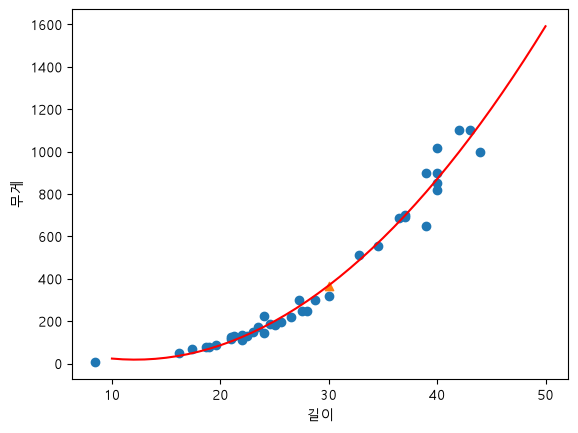

In [28]:
# 산점도 그래프
plt.scatter(train_data,train_label)
plt.scatter(30,367,marker="^")

plt.plot(point,point**2*lr.coef_[0]+point*lr.coef_[1]+lr.intercept_,color='r')
#x좌표(point),y좌표(ax**(point**2*lr.coef_[0]+point)+bx(point*lr.coef_[1])+c(lr.intercept_))
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()